In [2]:
import pandas as pd

file_path = "data/nyc311_2024_500k_raw.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 500000
Columns: 14


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,location_type,incident_zip,status,borough,latitude,longitude,open_data_channel_type
0,59894610,2024-01-01T00:00:00.000,2024-01-02T09:46:32.000,DOHMH,Department of Health and Mental Hygiene,Food Poisoning,1 or 2,Restaurant/Bar/Deli/Bakery,10304.0,Closed,STATEN ISLAND,40.628828,-74.074387,ONLINE
1,59896272,2024-01-01T00:00:00.000,2024-01-02T00:00:01.000,DOHMH,Department of Health and Mental Hygiene,Food Poisoning,1 or 2,Restaurant/Bar/Deli/Bakery,11211.0,Closed,BROOKLYN,40.710675,-73.954050,ONLINE
2,59898042,2024-01-01T00:00:00.000,2024-01-02T09:24:45.000,DOHMH,Department of Health and Mental Hygiene,Food Poisoning,1 or 2,Restaurant/Bar/Deli/Bakery,10462.0,Closed,BRONX,40.845340,-73.865594,ONLINE
3,59899838,2024-01-01T00:00:00.000,2024-01-02T09:42:25.000,DOHMH,Department of Health and Mental Hygiene,Food Poisoning,1 or 2,Restaurant/Bar/Deli/Bakery,10022.0,Closed,MANHATTAN,40.759192,-73.962290,ONLINE
4,59887043,2024-01-01T00:00:20.000,2024-01-01T00:41:01.000,NYPD,New York City Police Department,Illegal Fireworks,NaN,Street/Sidewalk,11228.0,Closed,BROOKLYN,40.627094,-74.014497,ONLINE


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   unique_key              500000 non-null  int64  
 1   created_date            500000 non-null  object 
 2   closed_date             494960 non-null  object 
 3   agency                  500000 non-null  object 
 4   agency_name             500000 non-null  object 
 5   complaint_type          500000 non-null  object 
 6   descriptor              488059 non-null  object 
 7   location_type           440572 non-null  object 
 8   incident_zip            494629 non-null  float64
 9   status                  500000 non-null  object 
 10  borough                 500000 non-null  object 
 11  latitude                492437 non-null  float64
 12  longitude               492437 non-null  float64
 13  open_data_channel_type  500000 non-null  object 
dtypes: float64(3), int64

In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)
print(missing_values)

location_type             59428
descriptor                11941
latitude                   7563
longitude                  7563
incident_zip               5371
closed_date                5040
unique_key                    0
created_date                  0
agency                        0
agency_name                   0
complaint_type                0
status                        0
borough                       0
open_data_channel_type        0
dtype: int64


In [6]:
print("Borough counts:")
print(df["borough"].value_counts(dropna=False))

print("\nNumber of complaint types:")
print(df["complaint_type"].nunique())

print("\nNumber of agencies:")
print(df["agency"].nunique())

Borough counts:
borough
BROOKLYN         156796
QUEENS           116781
BRONX            105410
MANHATTAN        104068
STATEN ISLAND     16574
Unspecified         371
Name: count, dtype: int64

Number of complaint types:
180

Number of agencies:
14


In [7]:
df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
df["closed_date"] = pd.to_datetime(df["closed_date"], errors="coerce")

print("Earliest created date:", df["created_date"].min())
print("Latest created date:", df["created_date"].max())

Earliest created date: 2024-01-01 00:00:00
Latest created date: 2024-02-26 20:17:07


In [9]:
# Make a separate copy for cleaning
df_clean = df.copy()

# Remove rows missing the two fields we definitely need
df_clean = df_clean.dropna(subset=["borough", "complaint_type"])

# Keep only the 5 NYC boroughs
valid_boroughs = [
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "BRONX",
    "STATEN ISLAND"
]

df_clean = df_clean[df_clean["borough"].isin(valid_boroughs)]

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before cleaning: 500000
Rows after cleaning: 499629
Rows removed: 371


In [10]:
# Create useful time-based fields
df_clean["created_date"] = pd.to_datetime(df_clean["created_date"], errors="coerce")
df_clean["closed_date"] = pd.to_datetime(df_clean["closed_date"], errors="coerce")

df_clean["resolution_hours"] = (
    (df_clean["closed_date"] - df_clean["created_date"]).dt.total_seconds() / 3600
)

df_clean["hour_of_day"] = df_clean["created_date"].dt.hour
df_clean["day_of_week"] = df_clean["created_date"].dt.day_name()
df_clean["month"] = df_clean["created_date"].dt.month_name()

print(df_clean[[
    "created_date",
    "closed_date",
    "resolution_hours",
    "hour_of_day",
    "day_of_week",
    "month"
]].head())

         created_date         closed_date  resolution_hours  hour_of_day  \
0 2024-01-01 00:00:00 2024-01-02 09:46:32         33.775556            0   
1 2024-01-01 00:00:00 2024-01-02 00:00:01         24.000278            0   
2 2024-01-01 00:00:00 2024-01-02 09:24:45         33.412500            0   
3 2024-01-01 00:00:00 2024-01-02 09:42:25         33.706944            0   
4 2024-01-01 00:00:20 2024-01-01 00:41:01          0.678056            0   

  day_of_week    month  
0      Monday  January  
1      Monday  January  
2      Monday  January  
3      Monday  January  
4      Monday  January  


In [12]:
clean_file = "data/nyc311_2024_500k_clean.csv"

df_clean.to_csv(clean_file, index=False)

print("Cleaned file saved to:", clean_file)
print("Final rows:", len(df_clean))

Cleaned file saved to: data/nyc311_2024_500k_clean.csv
Final rows: 499629


In [13]:
print("\nTop complaint types:")
print(df_clean["complaint_type"].value_counts().head(10))

print("\nBorough counts:")
print(df_clean["borough"].value_counts())

print("\nTop agencies:")
print(df_clean["agency"].value_counts().head(10))

print("\nAverage resolution hours by borough:")
print(
    df_clean.groupby("borough")["resolution_hours"]
    .mean()
    .sort_values()
)


Top complaint types:
complaint_type
HEAT/HOT WATER          78837
Illegal Parking         75458
Noise - Residential     41544
Blocked Driveway        27112
UNSANITARY CONDITION    18082
PLUMBING                11413
PAINT/PLASTER           11118
Abandoned Vehicle       10789
Street Condition         9889
WATER LEAK               8805
Name: count, dtype: int64

Borough counts:
borough
BROOKLYN         156796
QUEENS           116781
BRONX            105410
MANHATTAN        104068
STATEN ISLAND     16574
Name: count, dtype: int64

Top agencies:
agency
NYPD     192263
HPD      157756
DSNY      41062
DOT       31088
DEP       23543
DOB       15111
DOHMH     11808
DPR       10606
TLC        5371
DHS        4151
Name: count, dtype: int64

Average resolution hours by borough:
borough
BRONX            243.081919
QUEENS           275.270580
BROOKLYN         315.759438
MANHATTAN        377.962121
STATEN ISLAND    418.382934
Name: resolution_hours, dtype: float64


In [14]:
print("Missing resolution hours:")
print(df_clean["resolution_hours"].isna().sum())

print("\nNegative resolution hours:")
print((df_clean["resolution_hours"] < 0).sum())

print("\nResolution hours statistics:")
print(
    df_clean["resolution_hours"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Missing resolution hours:
5029

Negative resolution hours:
253

Resolution hours statistics:
count    494600.000000
mean        307.098415
std        1162.269374
min       -8784.016667
50%          15.383194
75%          80.567639
90%         639.623611
95%        1668.057306
99%        5711.490947
max       23033.933333
Name: resolution_hours, dtype: float64


In [15]:
print("\nMedian resolution hours by borough:")

print(
    df_clean.groupby("borough")["resolution_hours"]
    .median()
    .sort_values()
)


Median resolution hours by borough:
borough
QUEENS            6.786111
BROOKLYN         11.095833
STATEN ISLAND    15.563611
MANHATTAN        21.807222
BRONX            24.597222
Name: resolution_hours, dtype: float64


In [16]:
longest_cases = df_clean[
    [
        "borough",
        "agency",
        "complaint_type",
        "created_date",
        "closed_date",
        "resolution_hours"
    ]
].sort_values("resolution_hours", ascending=False)

display(longest_cases.head(20))

,borough,agency,complaint_type,created_date,closed_date,resolution_hours
7265,QUEENS,DOT,Street Light Condition,2024-01-01 23:58:00,2026-08-18 17:54:00,23033.933333
52050,QUEENS,DPR,Overgrown Tree/Branches,2024-01-06 19:14:58,2026-08-14 07:39:36,22812.410556
105675,QUEENS,DOT,Street Light Condition,2024-01-12 14:23:00,2026-08-19 20:28:00,22806.083333
178898,BROOKLYN,DEP,Water Maintenance,2024-01-20 07:08:48,2026-08-19 20:15:00,22621.103333
137477,BROOKLYN,DOT,Street Light Condition,2024-01-16 11:02:00,2026-08-14 17:01:00,22589.983333
13865,MANHATTAN,DOT,Street Light Condition,2024-01-02 16:45:00,2026-07-30 16:50:00,22560.083333
204060,QUEENS,DOT,Street Light Condition,2024-01-22 21:37:00,2026-08-18 17:44:00,22532.116667
147377,QUEENS,DPR,Maintenance or Facility,2024-01-17 09:58:58,2026-08-10 16:43:04,22470.735000
283983,QUEENS,DOT,Street Light Condition,2024-01-31 16:32:00,2026-08-18 17:46:00,22321.233333
236309,QUEENS,DPR,Maintenance or Facility,2024-01-26 10:58:08,2026-08-10 11:00:01,22248.031389


In [17]:
df_resolution = df_clean[
    df_clean["resolution_hours"].notna() &
    (df_clean["resolution_hours"] >= 0)
].copy()

print("Main cleaned dataset:", len(df_clean))
print("Valid resolution dataset:", len(df_resolution))
print("Excluded from resolution analysis:", len(df_clean) - len(df_resolution))

Main cleaned dataset: 499629
Valid resolution dataset: 494347
Excluded from resolution analysis: 5282


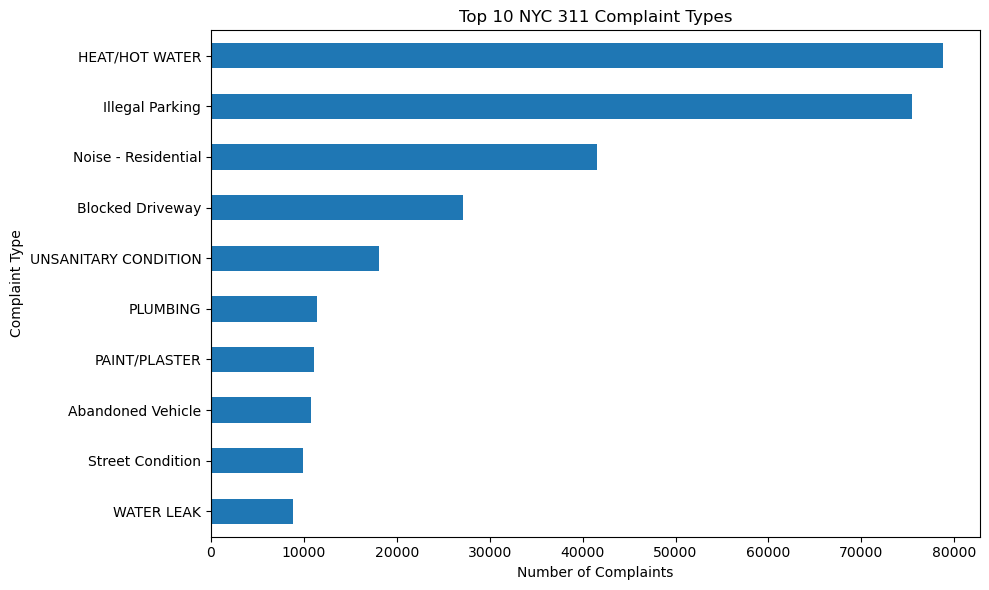

In [19]:
import matplotlib.pyplot as plt

top_complaints = df_clean["complaint_type"].value_counts().head(10)

plt.figure(figsize=(10,6))
top_complaints.sort_values().plot(kind="barh")

plt.title("Top 10 NYC 311 Complaint Types")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Type")

plt.tight_layout()
plt.show()

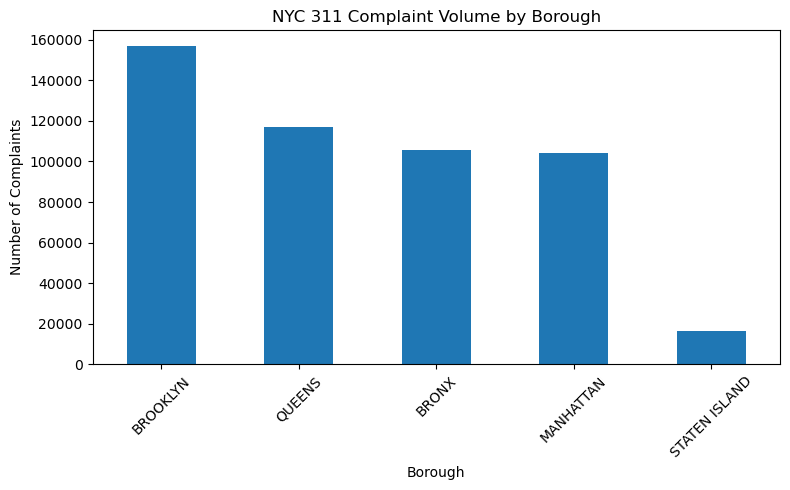

In [20]:
borough_counts = df_clean["borough"].value_counts()

plt.figure(figsize=(8,5))
borough_counts.plot(kind="bar")

plt.title("NYC 311 Complaint Volume by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

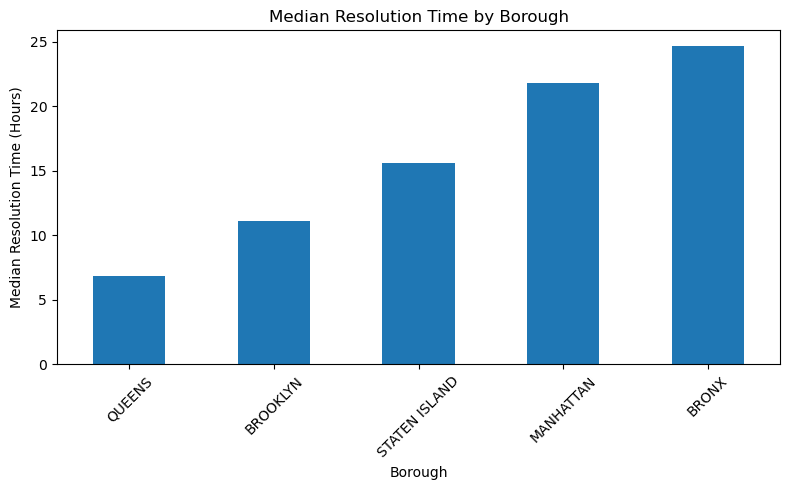

In [21]:
median_resolution = (
    df_resolution
    .groupby("borough")["resolution_hours"]
    .median()
    .sort_values()
)

plt.figure(figsize=(8,5))
median_resolution.plot(kind="bar")

plt.title("Median Resolution Time by Borough")
plt.xlabel("Borough")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

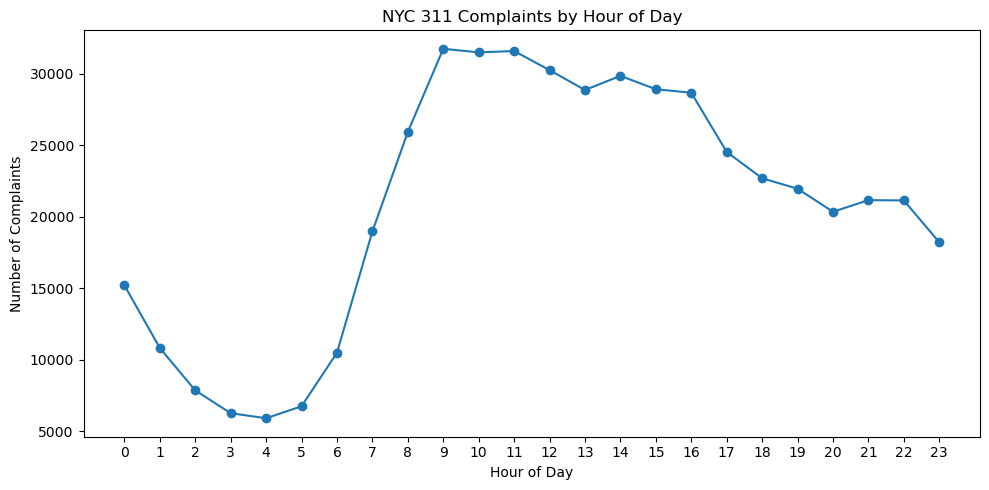

In [22]:
hourly_counts = (
    df_clean["hour_of_day"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10,5))
hourly_counts.plot(kind="line", marker="o")

plt.title("NYC 311 Complaints by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Complaints")

plt.xticks(range(0,24))
plt.tight_layout()
plt.show()


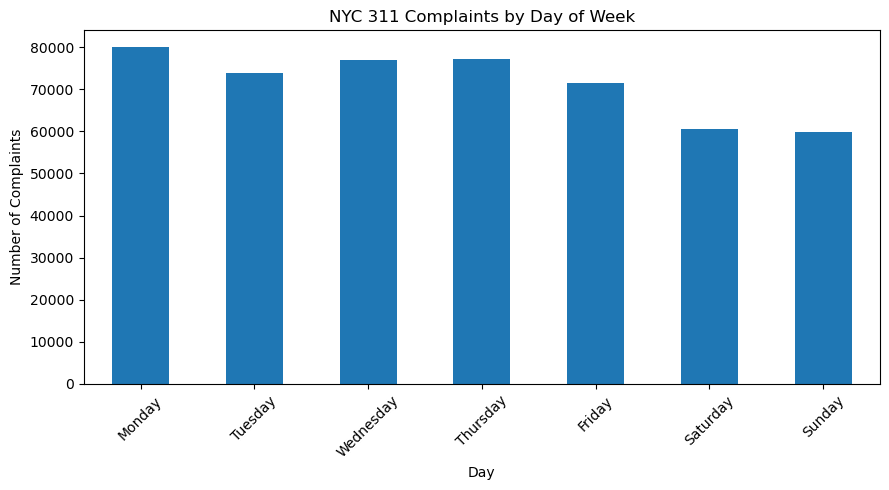

In [23]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_counts = (
    df_clean["day_of_week"]
    .value_counts()
    .reindex(day_order)
)

plt.figure(figsize=(9,5))
day_counts.plot(kind="bar")

plt.title("NYC 311 Complaints by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

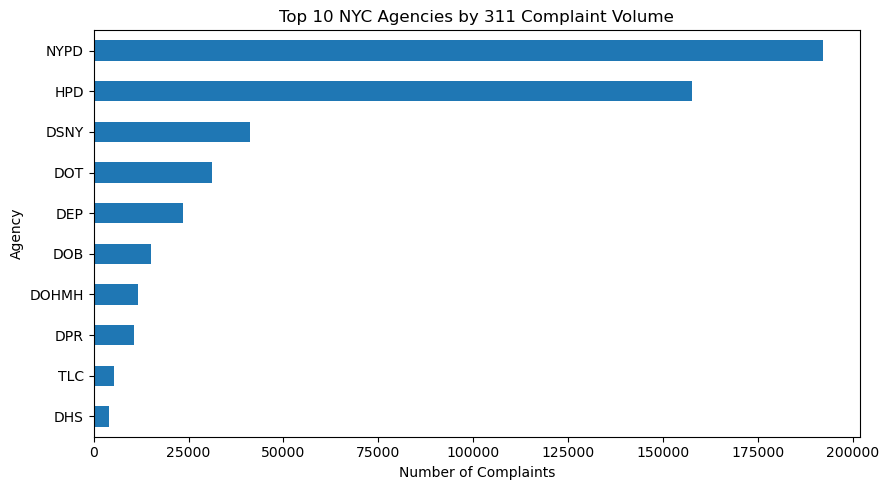

In [24]:
agency_counts = df_clean["agency"].value_counts().head(10)

plt.figure(figsize=(9,5))
agency_counts.sort_values().plot(kind="barh")

plt.title("Top 10 NYC Agencies by 311 Complaint Volume")
plt.xlabel("Number of Complaints")
plt.ylabel("Agency")

plt.tight_layout()
plt.show()

In [25]:
agency_resolution = (
    df_resolution
    .groupby("agency")["resolution_hours"]
    .agg(["count", "median"])
)

# Only agencies with at least 1,000 valid resolved requests
agency_resolution = agency_resolution[
    agency_resolution["count"] >= 1000
].sort_values("median")

print(agency_resolution)

         count       median
agency                     
NYPD    192263     0.834167
DHS       2024    14.938194
DEP      23312    23.583333
DOHMH    11275    24.000278
DOT      30530    30.603611
DSNY     40951    34.914722
HPD     157588    58.475556
DOB      15111   279.700833
DCWP      2217   289.923611
DPR       9769   334.922500
EDC       4063   783.554444
TLC       4956  2043.074444


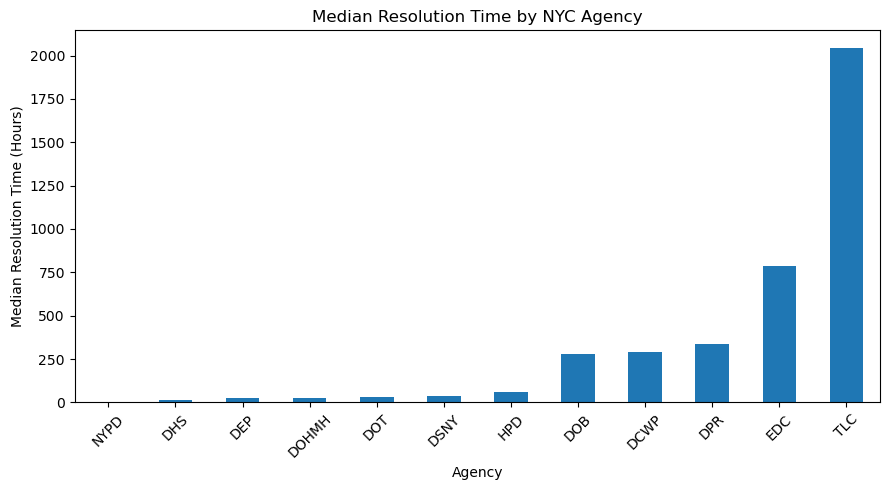

In [26]:
plt.figure(figsize=(9,5))

agency_resolution["median"].plot(kind="bar")

plt.title("Median Resolution Time by NYC Agency")
plt.xlabel("Agency")
plt.ylabel("Median Resolution Time (Hours)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
print("Peak complaint hour:")
print(hourly_counts.idxmax(), "-", hourly_counts.max(), "complaints")

print("\nBusiest day:")
print(day_counts.idxmax(), "-", day_counts.max(), "complaints")

print("\nHighest workload agency:")
print(agency_counts.idxmax(), "-", agency_counts.max(), "complaints")

print("\nSlowest median agency among agencies with 1,000+ resolved cases:")
print(
    agency_resolution["median"].idxmax(),
    "-",
    round(agency_resolution["median"].max(), 2),
    "hours"
)

Peak complaint hour:
9 - 31743 complaints

Busiest day:
Monday - 80006 complaints

Highest workload agency:
NYPD - 192263 complaints

Slowest median agency among agencies with 1,000+ resolved cases:
TLC - 2043.07 hours


In [28]:
tlc_cases = df_resolution[
    df_resolution["agency"] == "TLC"
]

print("TLC valid resolved cases:", len(tlc_cases))

print("\nTLC resolution statistics:")
print(
    tlc_cases["resolution_hours"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nTop TLC complaint types:")
print(tlc_cases["complaint_type"].value_counts().head(10))

TLC valid resolved cases: 4956

TLC resolution statistics:
count     4956.000000
mean      2021.317588
std       1421.308809
min          0.018056
50%       2043.074444
75%       2704.881597
90%       3733.326944
95%       4839.896528
99%       5886.437708
max      10478.322222
Name: resolution_hours, dtype: float64

Top TLC complaint types:
complaint_type
For Hire Vehicle Complaint    3315
Lost Property                  827
Taxi Complaint                 761
Green Taxi Complaint            43
Taxi Compliment                  8
FHV Licensee Complaint           2
Name: count, dtype: int64


In [29]:
print(
    agency_resolution.sort_values("median", ascending=False).head(10)
)

         count       median
agency                     
TLC       4956  2043.074444
EDC       4063   783.554444
DPR       9769   334.922500
DCWP      2217   289.923611
DOB      15111   279.700833
HPD     157588    58.475556
DSNY     40951    34.914722
DOT      30530    30.603611
DOHMH    11275    24.000278
DEP      23312    23.583333
